# Effect of SAM-F Parameters

This notebook evaluates the influence of the main parameters of the Segment Anything Model (SAM) automatic mask generator and the proposed SAM-F post-processing pipelin on grain segmentation.

The experiments investigate:

- the number of crop layers (`crop_n_layers`);
- the box non-maximum suppression threshold (`box_nms_thresh`);
- the crop non-maximum suppression threshold (`crop_nms_thresh`);
- the number of prompt points (`points_per_side`);
- the overlap-resolution threshold (`min_overlap_ratio`).

For each parameter configuration, the following quantities are computed:

- number of generated masks;
- image coverage;
- mask overlap;
- minimum detected grain area;
- computation time.

## 1. Imports and project modules

In [ ]:
import sys
sys.path.insert(0, "..")

from src.sam_pipeline import (load_sam_model, build_mask_generator, sam_masks_to_label_image)
from src.sam_filtering import (keep_largest_component, remove_overlapping_masks, filter_by_shape_labelmask)
from src.metrics import (coverage_union, coverage_labelmask, recouvrement)
from src.visualization import save_overlap_debug_csv

## 2. Load the SAM model

In [6]:
from pathlib import Path
import torch

PROJECT_ROOT = Path("..").resolve()

DATA_DIR = PROJECT_ROOT / "data" 
MODELS_DIR = PROJECT_ROOT / "models"

model_type = "vit_h"
SAM_CHECKPOINT = MODELS_DIR / "sam_vit_h_4b8939.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = load_sam_model(
    checkpoint=SAM_CHECKPOINT,
    model_type=model_type,
    device=device,
)

print(f"SAM {model_type} successfully loaded on {device}.")

print("Project root:", PROJECT_ROOT)
print("SAM checkpoint:", SAM_CHECKPOINT)

SAM vit_h successfully loaded on cuda.
Project root: /home/prof/mmohamad/zero_shot_granulometry_SAM
SAM checkpoint: /home/prof/mmohamad/zero_shot_granulometry_SAM/models/sam_vit_h_4b8939.pth


Image shape: (3000, 2200, 3)


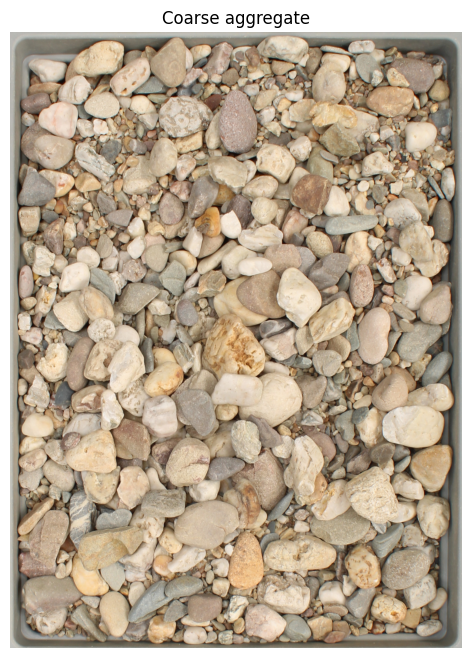

In [6]:
import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = DATA_DIR / "coarse" / "3.11.44.png"
image_bgr = cv2.imread(str(IMAGE_PATH))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Image shape:", image_rgb.shape)

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.title("Coarse aggregate")
plt.axis("off")
plt.show()

## 3. Experimental parameter grid

### 3.1 Parameters explored

- `points_per_side`: number of prompt points sampled along each image dimension by the SAM automatic mask generator.
- `min_overlap_ratio`: threshold $\mathrm{RS}_{\mathrm{th}}$ used by the Confidence-Guided Post-processing step of SAM-F. For two masks $M_i$ and $M_j$, the redundancy score  is defined as  
$$
RS(M_i,M_j) =
\frac{|M_i \cap M_j|}
{\min\left(|M_i|,|M_j|\right)}
$$.  
  When $ RS > \mathrm{RS}_{\mathrm{th}} $, the mask with the lower predicted IoU is removed.
- `area_frac_limit`: removes masks larger than this fraction of the image area
- `crop_n_layers`: number of recursive SAM crop layers. Additional crop layers improve the detection of small grains but increase computation time.
- `box_nms_thresh`: non-maximum suppression threshold applied to masks generated from the same crop.
- `crop_nms_thresh`: non-maximum suppression threshold applied to masks generated from different crops.
- `filtre2`: enables the Confidence-Guided Post-processing step.
- `filtre3`: enables the optional shape-based filtering step using solidity, eccentricity, and circularity.


The following lists define the parameter values explored. Multiple values can be specified for each parameter to evaluate their individual and combined effects on SAM segmentation.

In [3]:
points_per_side_list = [32]
min_overlap_ratio_list = [0.3]
area_frac_limit_list = [0.4]
crop_n_layers_list = [0,1]
box_nms_thresh_list = [0.3]
crop_nms_thresh_list = [0.3]
# Filter 2: confidence-guided overlap resolution
filtre2_list = [True] 
# Filter 3: optional shape filtering
filtre3_list = [False] 

### 3.2. Output table structure

The following list defines the columns of the CSV file used to store the parameters, processing time, mask statistics, coverage, overlap, minimum detected area, and output path for each experiment.

In [ ]:
global_fieldnames = [
    "exp_name",
    "image_name",

    # Experiment parameters
    "min_overlap_ratio",
    "area_frac_limit",
    "points_per_side",
    "box_nms_thresh",
    "crop_n_layers",
    "crop_nms_thresh",
    "use_filter2",
    "use_filter3",

    # Image dimensions
    "height",
    "width",
    "image_area",
    # Processing time
    "time_generate_min",

    # Mask counts
    "nb_masks_raw",
    "nb_masks_after_filter1",
    "nb_removed_filter1",
    "nb_masks_after_filter2",
    "nb_removed_filter2",
    "nb_masks_before_label",
    "nb_masks_after_label",
    "nb_lost_label",
    "nb_removed_filter3",
    "nb_final_labels",

    # Coverage and overlap
    "coverage_before_f2",
    "recouvrement_before_f2",
    "coverage_after_f2",
    "recouvrement_after_f2",
    "coverage_label_mask",       
    "coverage_after_f3",

    # Minimum detected area
    "min_area_raw",
    "A10_raw",
    "min_area_after_clean",
    "min_area_after_filter2",
    "min_area_after_label",
    "min_area_after_filter3",

    # Output file
    "pred_path",

]

### 3.3. Running the parameter experiments

In [ ]:
import os
import csv
import time
import cv2
import torch
import pickle
import itertools
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
from skimage.measure import regionprops
# =========================================================
# RUN THE PARAMETER EXPERIMENTS
# =========================================================
# Define input and output paths
dataset_path = DATA_DIR / "aggregates" / "coarse"  
# Example: process only the test split
# split_paths = [
#     os.path.join(dataset_path, "test"),
# ]

# Process the entire dataset
split_paths = [dataset_path]

global_csv_path = os.path.join(dataset_path, f"benchmark_sam_all_images_{model_type}.csv")

if not os.path.exists(global_csv_path):
    with open(global_csv_path, mode="w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=global_fieldnames)
        writer.writeheader()

# Generate all parameter combinations
all_combinations = list(itertools.product(
    min_overlap_ratio_list,
    area_frac_limit_list,
    points_per_side_list,
    crop_n_layers_list,
    filtre2_list,
    filtre3_list,
    box_nms_thresh_list,
    crop_nms_thresh_list
))
print(f"Total combinations to test : {len(all_combinations)}")

# Run each experimental configuration
for exp_idx, (min_overlap_ratio, area_frac_limit, points_per_side, crop_n_layers, use_filter2, use_filter3, box_nms_thresh, crop_nms_thresh) in enumerate(all_combinations, start=1):

    exp_name = (
        f"SAM_{model_type}_"
        f"mor{str(min_overlap_ratio).replace('.', 'p')}_"
        f"afl{str(area_frac_limit).replace('.', 'p')}_"
        f"pps{points_per_side}_"
        f"cnl{crop_n_layers}"
        f"nms{str(box_nms_thresh).replace('.', 'p')}_{str(crop_nms_thresh).replace('.', 'p')}"
        f"{'_T2' if use_filter2 else '_F2'}"
        f"{'_T3' if use_filter3 else '_F3'}"
    )

    print("\n" + "#" * 100)
    print(f"EXP {exp_idx}/{len(all_combinations)} : {exp_name}")
    print("#" * 100)

    mask_generator = build_mask_generator(
        sam_model=sam,
        points_per_side=points_per_side,
        box_nms_thresh=box_nms_thresh,
        crop_n_layers=crop_n_layers,
        crop_nms_thresh=crop_nms_thresh
    )

    # =====================================================
    # STEP 1: PREDICTION GENERATION
    # =====================================================
    for split_path in split_paths:

        output_dir = os.path.join(split_path, "predictions")
        os.makedirs(output_dir, exist_ok=True)


        print(f"\nSplit : {split_path}")
    

        for fname in sorted(os.listdir(split_path)):
            if not fname.lower().endswith((".jpg", ".png")):
                continue

            fpath = os.path.join(split_path, fname)

            image_bgr = cv2.imread(fpath)
            if image_bgr is None:
                print(f"Impossible de lire : {fpath}")
                continue

            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            h, w = image_rgb.shape[:2]
            image_area = h * w

            start_time = time.time()    

            masks = mask_generator.generate(image_rgb)
            nb_masks_raw = len(masks)

            end_time = time.time()
            elapsed_time = (end_time - start_time) / 60
            print(f"Image {fname} traitée en {elapsed_time:.2f} minutes")
    # =====================================================
    # STEP 2: LARGE-MASK REMOVAL AND COMPONENT CLEANING
    # =====================================================
            min_area_raw = min([m["area"] for m in masks]) if len(masks) > 0 else 0
            areas_raw = [m["area"] for m in masks]

            # Compute the 10th percentile of raw mask areas
            if len(areas_raw) > 0:
                area_p10_raw = np.percentile(areas_raw, 10)
            else:
                area_p10_raw = 0

            # Remove masks exceeding the allowed image-area fraction
            area_limit_pixels = area_frac_limit * image_area
            masks_after_filter1 = [
                m for m in masks
                if m.get("area", 0) <= area_limit_pixels
            ]
            nb_masks_after_filter1 = len(masks_after_filter1)
            nb_removed_filter1 = nb_masks_raw - nb_masks_after_filter1

            # Keep only the largest connected component of each mask
            cleaned_masks, removed_info = keep_largest_component(masks_after_filter1)
            min_area_after_clean = min([m["area"] for m in cleaned_masks]) if len(cleaned_masks) > 0 else 0


            if len(masks_after_filter1) > 0:
                coverage_before_f2 = coverage_union(masks_after_filter1, h, w, device=device)
                recouvrement_before_f2 = recouvrement(masks_after_filter1, h, w, device=device)
            else:
                coverage_before_f2 = 0.0
                recouvrement_before_f2 = 0.0
          
            if len(removed_info) > 0:
                print(f"  - keep_largest_component cleaned {len(removed_info)} multi-component masks")
    # =====================================================
    # STEP 3: CONFIDENCE-GUIDED OVERLAP RESOLUTION
    # =====================================================
            if use_filter2:
                start_filter2 = time.time()
                masks_after_filter2, removed_masks, debug_info, debug_kept_pairs = remove_overlapping_masks(
                    cleaned_masks,
                    device=device,
                    min_overlap_ratio=min_overlap_ratio
                )
                end_filter2 = time.time()
                elapsed_filter2 = (end_filter2 - start_filter2) / 60
                time_total_with_filter2_min = elapsed_time + elapsed_filter2
                print(f"Overlap resolution completed in "f"{elapsed_filter2:.2f} minutes")
                print(f"Total time with overlap resolution: {time_total_with_filter2_min:.2f} minutes")

                 # Save overlap-resolution diagnostic information
                debug_dir = os.path.join(output_dir, "debug_overlap", os.path.splitext(fname)[0])
                save_overlap_debug_csv(
                    debug_info=debug_info,
                    debug_kept_pairs=debug_kept_pairs,
                    out_dir=debug_dir,
                    prefix=os.path.splitext(fname)[0]
                )
                # Compute statistics after overlap resolution
                nb_masks_after_filter2 = len(masks_after_filter2)
                nb_removed_filter2 = len(removed_masks)
                min_area_after_filter2 = min([m["area"] for m in masks_after_filter2]) if len(masks_after_filter2) > 0 else 0
                # Save the filtered SAM masks
                pkl_name = os.path.splitext(fname)[0] + f"_{exp_name}_cleaned_masks_after_filter2.pkl"
                pkl_path = os.path.join(output_dir, pkl_name)

                with open(pkl_path, "wb") as f:
                    pickle.dump(masks_after_filter2, f)

                ###############################
                # Compute coverage and overlap after filtering
                if len(masks_after_filter2) > 0:
                    coverage_after_f2 = coverage_union(masks_after_filter2, h, w, device=device)
                    recouvrement_after_f2 = recouvrement(masks_after_filter2, h, w, device=device)
                else:
                    coverage_after_f2 = 0.0
                    recouvrement_after_f2 = 0.0
    # =====================================================
    # STEP 4: CONVERSION TO A NON-OVERLAPPING LABEL IMAGE
    # =====================================================
                label_mask = sam_masks_to_label_image(masks_after_filter2, image_rgb.shape)
                nb_masks_after_label = len(np.unique(label_mask)) - 1
                nb_lost_label = nb_masks_after_filter2 - nb_masks_after_label
                props = regionprops(label_mask)

                min_area_after_label = min([r.area for r in props]) if len(props) > 0 else 0
                

                coverage_label_mask = coverage_labelmask(label_mask, device=device)
    # =====================================================
    # STEP 5: OPTIONAL SHAPE-BASED FILTERING
    # =====================================================
                if use_filter3:     
                    label_mask, kept, removed = filter_by_shape_labelmask(label_mask,
                        min_solidity=0.70,
                        max_eccentricity=1.0,  
                        min_circularity=0.10
                    )
                    nb_removed_filter3 = len(removed)
                    props_after_f3 = regionprops(label_mask)
                    min_area_after_filter3 = min([r.area for r in props_after_f3]) if len(props_after_f3) > 0 else 0
                else:
                    nb_removed_filter3 = 0
                    min_area_after_filter3 = ""
    # =====================================================
    # STEP 6: SAVE THE FINAL SEGMENTATION
    # =====================================================
                coverage_after_f3 = coverage_labelmask(label_mask, device=device)

                out_name = os.path.splitext(fname)[0] + f"_{exp_name}_pred.tif"
                out_path = os.path.join(output_dir, out_name)
                tiff.imwrite(out_path, label_mask.astype(np.int32))

                nb_final_labels = len(np.unique(label_mask)) - 1  

            # Save cleaned masks when overlap resolution is disabled
            else: 
                pkl_name = os.path.splitext(fname)[0] + f"_{exp_name}_cleaned_masks.pkl"
                pkl_path = os.path.join(output_dir, pkl_name)

                with open(pkl_path, "wb") as f:
                    pickle.dump(cleaned_masks, f)
                out_path = pkl_path
                min_area_after_filter2=""
                min_area_after_filter3=""
                min_area_after_filter3 =""
                min_area_after_label = ""
                nb_removed_filter2 = ""
                masks_after_filter2 = ""
                coverage_after_f2 = ""
                nb_masks_after_filter2 = ""
                recouvrement_after_f2 = ""
                coverage_label_mask = ""
                nb_masks_after_label = ""
                nb_lost_label = ""
                nb_removed_filter3 = ""
                coverage_after_f3 = ""
                nb_final_labels = ""
                


# =====================================================
# STEP 7: SAVE EXPERIMENT METRICS
# =====================================================
            row_global = {
                "exp_name": exp_name,
                "image_name": fname,

                "min_overlap_ratio": min_overlap_ratio,
                "area_frac_limit": area_frac_limit,
                "points_per_side": points_per_side,
                "box_nms_thresh": box_nms_thresh,
                "crop_n_layers": crop_n_layers,
                "crop_nms_thresh": crop_nms_thresh,
                "use_filter2": use_filter2,
                "use_filter3": use_filter3,

                "height": h,
                "width": w,
                "image_area": image_area,
                "A10_raw": round(area_p10_raw, 1),
                "time_generate_min": round(elapsed_time, 2),
                

                "nb_masks_raw": nb_masks_raw,
                "nb_masks_after_filter1": nb_masks_after_filter1,
                "nb_removed_filter1": nb_removed_filter1,
                "nb_masks_after_filter2": nb_masks_after_filter2,
                "nb_removed_filter2": nb_removed_filter2,
                "nb_masks_before_label": nb_masks_after_filter2,
                "nb_masks_after_label": nb_masks_after_label,
                "nb_lost_label": nb_lost_label,
                "nb_removed_filter3": nb_removed_filter3,
                "nb_final_labels": nb_final_labels,

                "coverage_before_f2": coverage_before_f2,
                "recouvrement_before_f2": recouvrement_before_f2,
                "coverage_after_f2": coverage_after_f2,
                "recouvrement_after_f2": recouvrement_after_f2,
                "coverage_label_mask": coverage_label_mask,
                "coverage_after_f3": coverage_after_f3,

                "min_area_raw": min_area_raw,
                "min_area_after_clean": min_area_after_clean,
                "min_area_after_filter2": min_area_after_filter2,   
                "min_area_after_label": min_area_after_label,
                "min_area_after_filter3": min_area_after_filter3,

                "pred_path": out_path,
            }

            with open(global_csv_path, mode="a", newline="", encoding="utf-8") as f:
                writer = csv.DictWriter(f, fieldnames=global_fieldnames)
                writer.writerow(row_global)
        print(f"\nAll images from {split_path} were processed for the experiment {exp_name}.")
        print(f"Metrics saved to CSV global : {global_csv_path}")


print("\n" + "#" * 100)
print("BENCHMARK COMPLETED")
print("#" * 100)